In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import shapiro, kstest, probplot
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.graphics.gofplots import qqplot

### Carga dos Dados

In [23]:
# Abrir o dataset
df_farm = pd.read_csv('./dados_de_irrigacao.csv')

In [24]:
# Checar estrutura do Dataset
df_farm.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Horas de Irrigação        299 non-null    int64  
 1   Área Irrigada             299 non-null    int64  
 2   Área Irrigada por Ângulo  299 non-null    float64
dtypes: float64(1), int64(2)
memory usage: 7.1 KB


In [25]:
# Visualizar Topo do DataFrame
df_farm.head(10)

,Horas de Irrigação,Área Irrigada,Área Irrigada por Ângulo
0,1,100,66.666667
1,2,200,133.333333
2,3,300,200.000000
3,4,400,266.666667
4,5,500,333.333333
5,6,600,400.000000
6,7,700,466.666667
7,8,800,533.333333
8,9,900,600.000000
9,10,1000,666.666667


In [26]:
# Visualizar final do Dataset
df_farm.tail(10)

,Horas de Irrigação,Área Irrigada,Área Irrigada por Ângulo
289,290,29000,19333.333333
290,291,29100,19400.000000
291,292,29200,19466.666667
292,293,29300,19533.333333
293,294,29400,19600.000000
294,295,29500,19666.666667
295,296,29600,19733.333333
296,297,29700,19800.000000
297,298,29800,19866.666667
298,299,29900,19933.333333


### EDA

In [27]:
# Medidas estatísticas das variáveis
df_farm.describe()

,Horas de Irrigação,Área Irrigada,Área Irrigada por Ângulo
count,299.000000,299.000000,299.000000
mean,150.000000,15000.000000,10000.000000
std,86.458082,8645.808233,5763.872155
min,1.000000,100.000000,66.666667
25%,75.500000,7550.000000,5033.333333
50%,150.000000,15000.000000,10000.000000
75%,224.500000,22450.000000,14966.666667
max,299.000000,29900.000000,19933.333333


<Axes: xlabel='Horas de Irrigação', ylabel='Área Irrigada'>

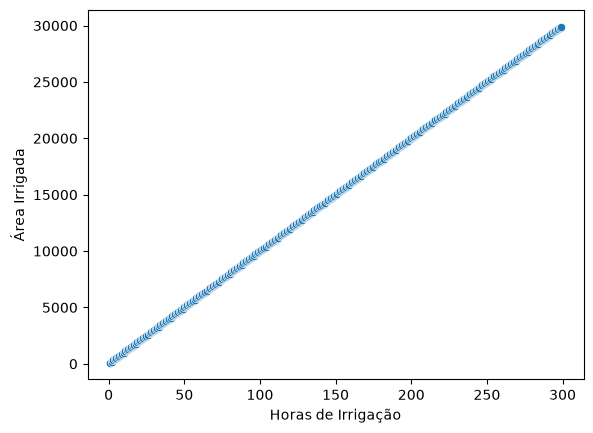

In [28]:
# Plot de Dispersão
# X = Horas de Irrigação
# Y = Área Irrigada
sns.scatterplot(data=df_farm, x='Horas de Irrigação', y='Área Irrigada')

<Axes: xlabel='Horas de Irrigação', ylabel='Área Irrigada por Ângulo'>

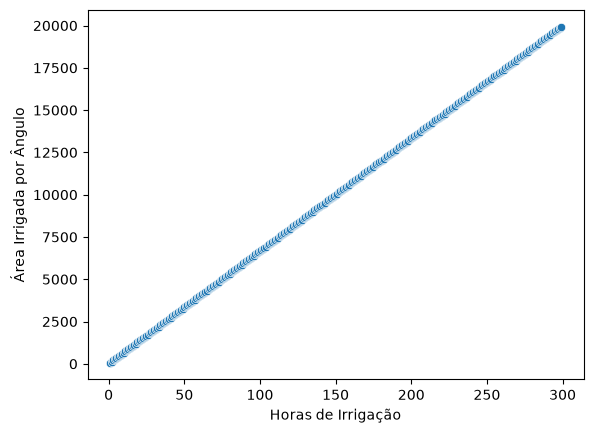

In [29]:
# Plot de Dispersão
# X = Horas de Irrigação
# Y = Área Irrigada por Ângulo
sns.scatterplot(data=df_farm, x='Horas de Irrigação', y='Área Irrigada por Ângulo')

<Axes: ylabel='Horas de Irrigação'>

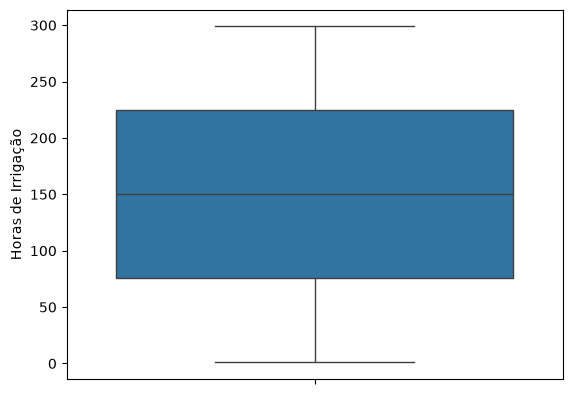

In [30]:
# Verificar se temos Outliers - Horas de Irrigação
# Plot BoxPlot
sns.boxplot(df_farm, y='Horas de Irrigação')

<Axes: ylabel='Área Irrigada'>

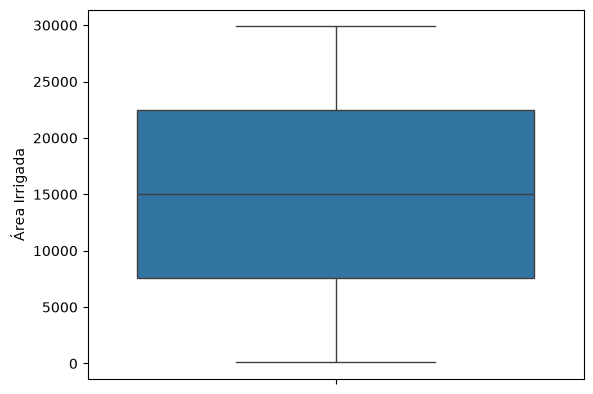

In [31]:
# Verificar se temos Outliers - Área Irrigada
# Plot BoxPlot
sns.boxplot(df_farm, y='Área Irrigada')

<Axes: ylabel='Área Irrigada por Ângulo'>

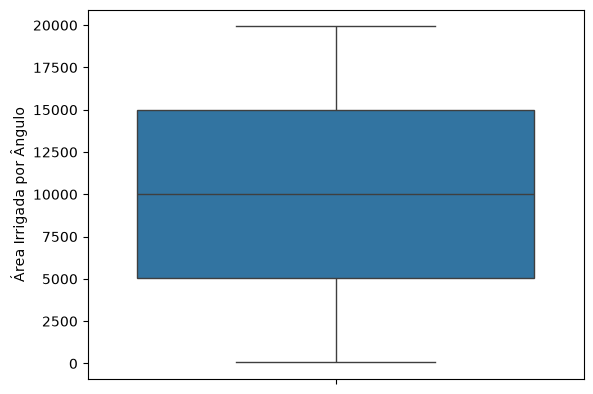

In [32]:
# Verificar se temos Outliers - Área Irrigada por Ângulo
# Plot BoxPlot
sns.boxplot(df_farm, y='Área Irrigada por Ângulo')

<Axes: >

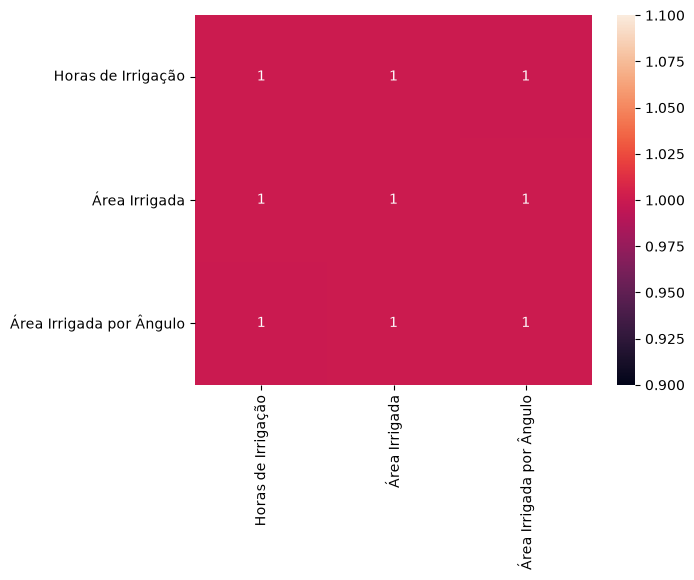

In [33]:
# Verificar Correlação - Pearson
sns.heatmap(df_farm.corr('pearson'), annot=True)

<Axes: >

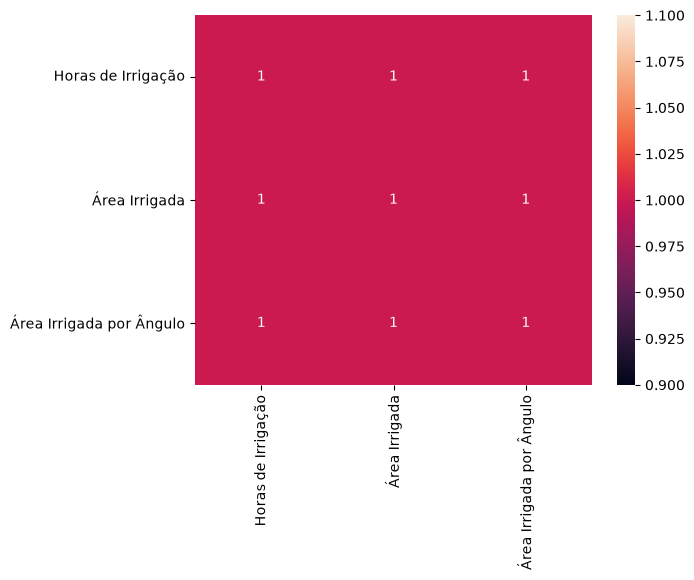

In [34]:
# Verificar Correlação - Spearman
sns.heatmap(df_farm.corr('spearman'), annot=True)

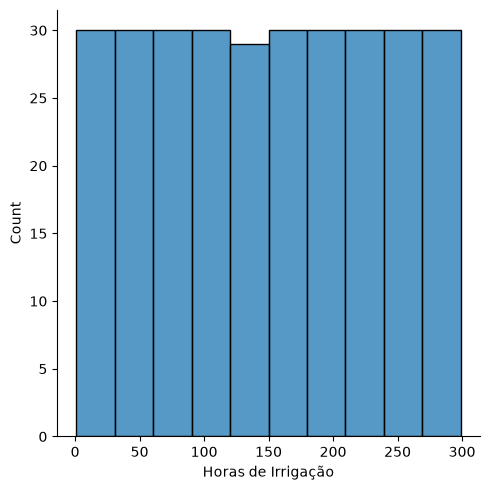

In [35]:
# Histograma das variáveis - Horas de Irrigação
sns.displot(df_farm, x='Horas de Irrigação')

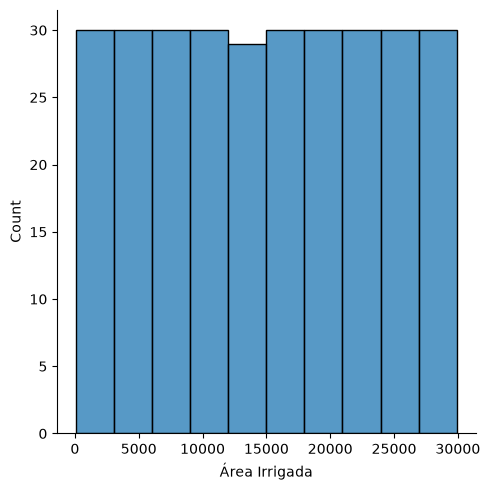

In [36]:
# Histograma das variáveis - Área Irrigação
sns.displot(df_farm, x='Área Irrigada')

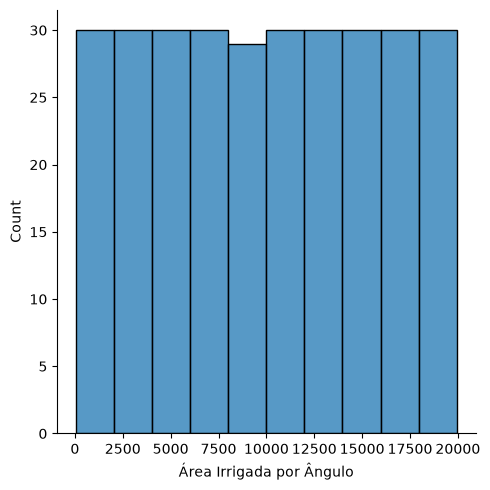

In [37]:
# Histograma das variáveis - Área Irrigação por Ângulo
sns.displot(df_farm, x='Área Irrigada por Ângulo')

### Treinar Modelo

In [61]:
# Dividir dataset entre treino e teste
x = df_farm.drop(columns=['Horas de Irrigação'])
y = df_farm['Horas de Irrigação']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [62]:
len(x_train), len(x_test), len(y_train), len(y_test)

(209, 90, 209, 90)

In [63]:
# Treinar o modelo de Regressão Linear - Modelo 1
reg_model = LinearRegression()

In [64]:
reg_model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.01,0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Área Irrigada','Área Irrigada por Ângulo']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-5.684e-14
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [72]:
# Imprimir Equação da Reta
# y = ax + b
print("A Equação da reta é y = {:4f}x + {:4f}".format(reg_model.coef_[0], reg_model.intercept_))

A Equação da reta é y = 0.006923x + -0.000000


### Validar Modelo - Métricas

In [73]:
# Predição dos valores com base no conjunto de testes
y_pred = reg_model.predict(x_test)

In [79]:
# Calcular métrica R-squared ou Coeficiente de Determinação
# R2 representa a proporção na variação na variável dependente que é explicada pela variável independente
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error
r2_score(y_test, y_pred)

1.0

In [75]:
# Calcular métrica MAE (Mean Absolute Error)
# MAE - Média (y_test - y_pred)
# É uma métrica fácil de interpretar
# MAE é menos sensível a Outliers
mean_absolute_error(y_test, y_pred)

2.4938076295357962e-14

In [76]:
# Calcular métrica MSE (Mean Squared Error)
# MSE = Média (y_test - y_pred)2
# Não é uma métrica fácil de interpretar
# MSE é mais sensível a Outliers e penaliza grandes erros
mean_squared_error(y_test, y_pred)

1.1011534073556721e-27

In [80]:
# Calcular métrica RMSE (Square Root Mean Squared Error)
# RMSE = Raiz (Média (y_test - y_pred)2)
# É uma métrica fácil de interpretar
# MSE é mais sensível a Outliers e penaliza grandes erros
root_mean_squared_error(y_test, y_pred)

3.318363161794791e-14

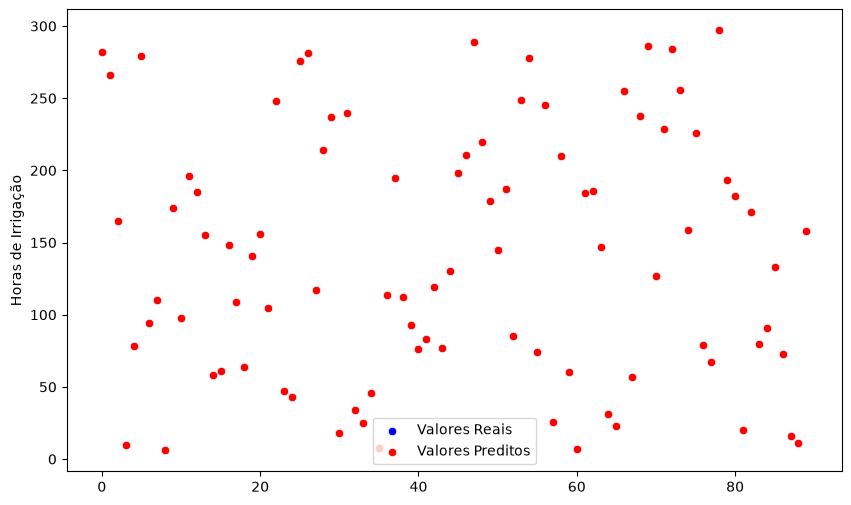

In [89]:
# Análise Gráfica
x_axis = range(len(y_test))
plt.figure(figsize=(10,6))
sns.scatterplot(x=x_axis, y=y_test, color='blue', label='Valores Reais')
sns.scatterplot(x=x_axis, y=y_pred, color='red', label='Valores Preditos')
plt.legend()
plt.show()

### Analise de Resíduos

In [90]:
# Calcular resíduos
residuos = y_test - y_pred

In [92]:
# Calcular os resíduos padronizados (standandization)
# Para cada elemento de um conjunto (x - média) / desvio_padrao
from scipy.stats import zscore
residuos_std = zscore(residuos)

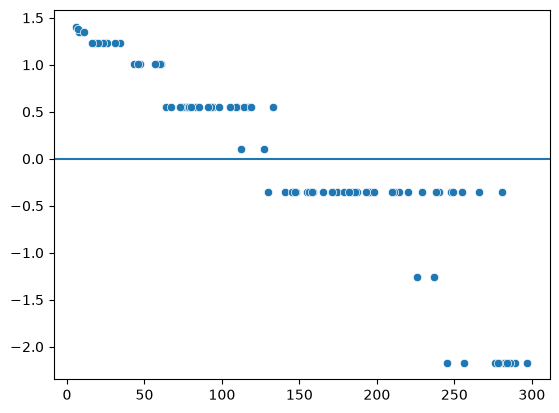

In [93]:
# Verificar linearidade do modelo:
# Se os resíduos estiverem entre -2 e +2 (na escala padrão) - indica linearidade

# Verificar homogeneidade das variâncias (Homocedasticidade)
# Valores estiver em torno da reta, temos homocedasticidade, caso contrário
# Se tivermos alguma tendência ou padrão (formam um cone, funil), há heterocedasticidade

sns.scatterplot(x=y_pred.reshape(-1), y=residuos_std.reshape(-1))
plt.axhline(y=0)

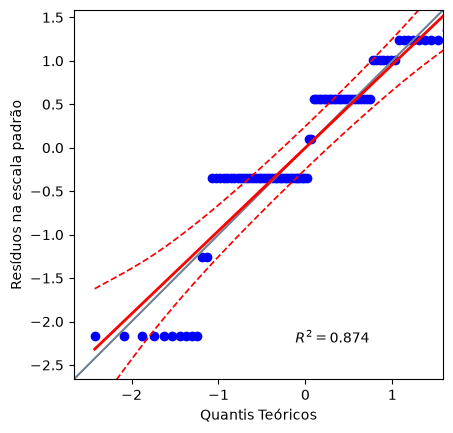

In [94]:
# Checar se resíduos seguem uma distribuição normal
# QQ (Quantile-Quantile) Plot, que avalia se uma amostra segue uma distribuição normal
import pingouin as pg

pg.qqplot(residuos_std, dist='norm', confidence=0.95)
plt.xlabel('Quantis Teóricos')
plt.ylabel('Resíduos na escala padrão')
plt.show()

In [99]:
# Teste de Normalidade = Shapiro Wilk
# H0 - Segue distribuição normal
# H1 - Não segue distribuição normal
# Se o p-valor > 0.05 não rejeita H0, caso contrário rejeitamos
stat_shapiro, p_valor_shapiro = shapiro(residuos)
print("Estatística do teste: {} e P-Valor: {}".format(stat_shapiro, p_valor_shapiro))

Estatística do teste: 0.8670642324500225 e P-Valor: 1.7849648713217148e-07


In [100]:
# Teste de Normalidade = Kolmogorov-Smirnov
# H0 - Segue distribuição normal
# H1 - Não segue distribuição normal
# Se o p-valor > 0.05 não rejeita H0, caso contrário rejeitamos
stat_ks, p_valor_ks = kstest(residuos, 'norm')
print("Estatística do teste: {} e P-Valor: {}".format(stat_ks, p_valor_ks))

Estatística do teste: 0.499999999999978 e P-Valor: 2.486951501583832e-21


### Fazer predições com o modelo

In [108]:
# Se eu estudar 3.4 horas, qual a pontuação prevista pelo modelo?
reg_model.predict([[15, 8]])

c:\Users\jfbonacasata\.virtualenvs\dataset_fazenda-6pR6KvzZ\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([0.14076923])